# Sample properties · magnitude and redshift

The former Figure 1 panels c,d, now one separate horizontal figure. No figure
or panel titles; labels, legends and binning are preserved. Train/validation
metadata only. No image mosaics or model outputs are needed.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 2.8)
PROPERTY_SPLITS = ['train', 'validation']
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid


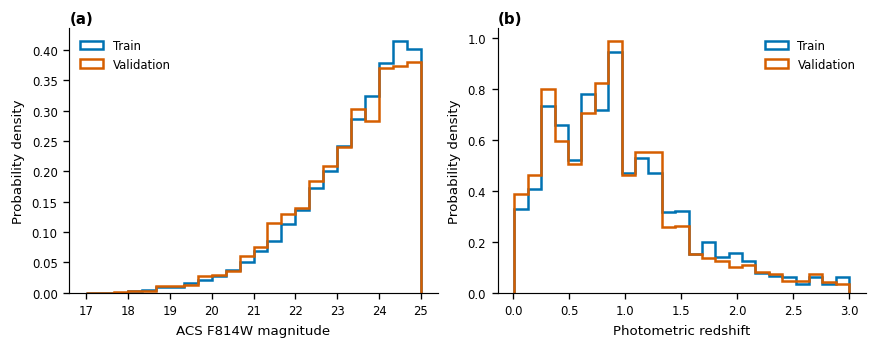

In [3]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
population = objects[objects.split.isin(PROPERTY_SPLITS)]
mag_bins = np.linspace(np.floor(population.ACS_F814W_MAG.min()), 25, 25)
z_bins = np.linspace(.01, 3, 26)
for ax, column, bins, xlabel, letter, title in [
    (axes[0], 'ACS_F814W_MAG', mag_bins, 'ACS F814W magnitude', 'a', 'Optical selection'),
    (axes[1], 'ez_z_phot', z_bins, 'Photometric redshift', 'b', 'Redshift distribution')]:
    for split in PROPERTY_SPLITS:
        data = objects.loc[objects.split == split, column].dropna()
        ax.hist(data, bins=bins, density=True, histtype='step', linewidth=1.5,
                color=COLORS[split], label=split.capitalize())
    ax.set(xlabel=xlabel, ylabel='Probability density')
    ax.legend(frameon=False)
    ax.text(0, 1.02, f'({letter})', transform=ax.transAxes, fontsize=9, fontweight='bold')
plt.show()


In [4]:
paths = export(fig, f'fig01b_sample_properties_{VERSION}', '01b_sample_properties.ipynb',
    [manifest_path, objects_path],
    dict(figsize=FIGSIZE, property_splits=PROPERTY_SPLITS,
         magnitude_bins=mag_bins.tolist(), redshift_bins=z_bins.tolist()),
    status='sample properties: separate horizontal figure, train/validation metadata only')

Exported: fig01b_sample_properties_v01.pdf, fig01b_sample_properties_v01.svg, fig01b_sample_properties_v01.png


## Working caption

Optical-magnitude (a) and photometric-redshift (b) distributions of the matched
training and validation samples. Each histogram is normalized to unit integral
with shared bins between splits. The ACS F814W magnitude cut is 25, and the
selected photometric-redshift range is 0.01–3. The sample is optically selected,
not a NISP-complete galaxy sample. Reserved-test property distributions are
not shown. Figure numbering is provisional.